# TF-IDF + Linear SVM

In [1]:
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("bethesda-classification")

print("MLflow tracking URI:", mlflow.get_tracking_uri())

/Users/savely/Desktop/diploma/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow tracking URI: http://127.0.0.1:5000


## Служебная информация об эксперименте

Фиксируем имя участника, название задачи, дату и текущий Git commit.

Git commit используется как идентификатор версии кода. Перед запуском модели
необходимо убедиться, что код эксперимента закоммичен. Если в рабочей директории
есть незакоммиченные изменения, текущий commit не полностью описывает состояние
кода, на котором выполняется эксперимент.

In [9]:
import subprocess
from datetime import datetime


participant = "Savely"
task_name = "bethesda-classification"

# Получаем SHA текущего Git-коммита
git_commit = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    text=True,
).strip()

# Проверяем наличие незакоммиченных изменений
git_status = subprocess.check_output(
    ["git", "status", "--porcelain"],
    text=True,
).strip()

run_date = datetime.now().strftime("%d-%m-%Y")

print("Participant:", participant)
print("Task:", task_name)
print("Date:", run_date)
print("Git commit:", git_commit)

if git_status:
    print("\nWARNING: в репозитории есть незакоммиченные изменения.")
    print("Перед первым MLflow run необходимо сделать commit и повторно выполнить эту ячейку.")
else:
    print("\nGit working tree clean.")

Participant: Savely
Task: bethesda-classification
Date: 14-10-2026
Git commit: 01cc55bb2244f1b027f65253e425d222bdfc43a1

Перед первым MLflow run необходимо сделать commit и повторно выполнить эту ячейку.


## Версия датасета

Для экспериментов используется актуальный `prepared_dataset.csv`.

Версия данных определяется полным SHA256-хешем файла. Если содержимое датасета
изменится хотя бы на уровне одного байта, изменится и его SHA256.

Полный SHA256 будет сохраняться в каждом MLflow run как `dataset_version`.
Первые 12 символов используются только для удобного отображения и имени
архивной копии датасета.

In [3]:
from pathlib import Path

from src.common.dataset_versioning import calculate_sha256


# Определяем корень проекта
PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = next(
        path
        for path in PROJECT_ROOT.parents
        if (path / "src").exists()
    )

# Актуальный воспроизводимый датасет
dataset_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "prepared_dataset.csv"
)

if not dataset_path.exists():
    raise FileNotFoundError(
        f"Датасет не найден: {dataset_path}"
    )

# Вычисляем версию данных
dataset_hash = calculate_sha256(dataset_path)
dataset_version_short = dataset_hash[:12]

# Ожидаемая архивная копия этой версии
dataset_version_path = (
    dataset_path.parent
    / "versions"
    / f"{dataset_path.stem}_{dataset_version_short}{dataset_path.suffix}"
)

print("Dataset:", dataset_path.name)
print("Dataset version:", dataset_version_short)
print("Full SHA256:", dataset_hash)
print("Archived version:", dataset_version_path.name)
print("Archive exists:", dataset_version_path.exists())

Dataset: prepared_dataset.csv
Dataset version: e88b34b729ea
Full SHA256: e88b34b729eaf057b6f2a7deeae7fcfce901da710ddce628a329d9d96aaad724
Archived version: prepared_dataset_e88b34b729ea.csv
Archive exists: True


## Загрузка и первичная проверка датасета

Загрузим актуальный `prepared_dataset.csv`, для которого выше был вычислен
SHA256-хеш.

Проверим размер датасета, структуру столбцов и первые строки. На этом этапе
модель ещё не обучается, поэтому отдельный MLflow run не создаётся.

In [4]:
import pandas as pd

df = pd.read_csv(dataset_path, sep=";")

print("Путь к датасету:", dataset_path)
print("Размер датасета:", df.shape)
print("Столбцы:", df.columns.tolist())

Путь к датасету: /Users/savely/Desktop/diploma/data/processed/prepared_dataset.csv
Размер датасета: (5613, 8)
Столбцы: ['case_id', 'source_table', 'source_row', 'description', 'conclusion', 'bethesda', 'duplicate_group', 'duplicate_type']


## Проверка структуры и качества данных

Перед построением модели проверим:

- наличие необходимых столбцов;
- количество пропущенных значений;
- число объектов каждого класса Bethesda;
- долю каждого класса в датасете.

Это позволит оценить состояние нового датасета и степень дисбаланса классов
перед разделением на train и test.

In [5]:
print("Столбцы:")
print(df.columns.tolist())

print("\nПропущенные значения:")
print(df.isna().sum())

print("\nКоличество объектов каждого класса Bethesda:")
print(df["bethesda"].value_counts().sort_index())

print("\nДоля каждого класса:")
print(
    df["bethesda"]
    .value_counts(normalize=True)
    .sort_index()
    .round(4)
)

Столбцы:
['case_id', 'source_table', 'source_row', 'description', 'conclusion', 'bethesda', 'duplicate_group', 'duplicate_type']

Пропущенные значения:
case_id               0
source_table          0
source_row            0
description           0
conclusion            0
bethesda              0
duplicate_group    5603
duplicate_type     5603
dtype: int64

Количество объектов каждого класса Bethesda:
bethesda
I       575
II     3825
III     286
IV      559
V       172
VI      196
Name: count, dtype: int64

Доля каждого класса:
bethesda
I      0.1024
II     0.6815
III    0.0510
IV     0.0996
V      0.0306
VI     0.0349
Name: proportion, dtype: float64


## Проверка дубликатов

В актуальном датасете информация о найденных дубликатах сохраняется в полях
`duplicate_group` и `duplicate_type`.

Дубликаты не удаляются автоматически на этапе подготовки данных. Перед обучением
необходимо проверить найденные группы и исключить ситуацию, когда одинаковые
описания попадают одновременно в обучающую и тестовую выборки.

Дополнительно проверим уникальность `case_id`, наличие полных дубликатов строк
и повторяющихся значений `description`.

In [6]:
# Проверяем уникальность идентификаторов
duplicate_case_ids = df["case_id"].duplicated().sum()

# Проверяем полные дубликаты строк
duplicate_rows = df.duplicated().sum()

# Проверяем одинаковые description
duplicate_descriptions = df["description"].duplicated().sum()

# Выбираем записи, для которых задана группа дубликатов
marked_duplicates = df[
    df["duplicate_group"].notna()
].copy()

print("Дубликаты case_id:", duplicate_case_ids)
print("Полные дубликаты строк:", duplicate_rows)
print("Повторяющиеся description:", duplicate_descriptions)

print("\nСтрок с duplicate_group:", len(marked_duplicates))
print(
    "Количество групп дубликатов:",
    marked_duplicates["duplicate_group"].nunique()
)

print("\nТипы дубликатов:")
print(
    marked_duplicates["duplicate_type"]
    .value_counts(dropna=False)
)

Дубликаты case_id: 0
Полные дубликаты строк: 0
Повторяющиеся description: 0

Строк с duplicate_group: 10
Количество групп дубликатов: 10

Типы дубликатов:
duplicate_type
technical    10
Name: count, dtype: int64


## Разделение данных на обучающую и тестовую выборки

Для классификации используется только поле `description`.
Поле `bethesda` является целевой переменной.

Служебные поля `case_id`, `source_table`, `source_row`, `duplicate_group`
и `duplicate_type`, а также поле `conclusion`, в признаки модели не включаются.

Перед разделением было подтверждено отсутствие повторяющихся `description`,
поэтому одинаковые тексты не могут одновременно попасть в train и test.

Данные разделяются в отношении 80/20 со стратификацией по Bethesda.
Параметр `random_state=42` фиксируется для воспроизводимости эксперимента.

In [7]:
from sklearn.model_selection import train_test_split


# Вход модели - только цитологическое описание
X = df["description"]

# Целевая переменная - категория Bethesda
y = df["bethesda"]

# Стратифицированное разделение на train и test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Размер всей выборки:", len(X))
print("Размер train:", len(X_train))
print("Размер test:", len(X_test))

print("\nРаспределение классов в train:")
print(y_train.value_counts().sort_index())

print("\nРаспределение классов в test:")
print(y_test.value_counts().sort_index())

Размер всей выборки: 5613
Размер train: 4490
Размер test: 1123

Распределение классов в train:
bethesda
I       460
II     3060
III     229
IV      447
V       137
VI      157
Name: count, dtype: int64

Распределение классов в test:
bethesda
I      115
II     765
III     57
IV     112
V       35
VI      39
Name: count, dtype: int64


## Эксперимент 1: Word + Character TF-IDF + Linear SVM

В первом эксперименте используется линейный метод опорных векторов (Linear SVM) для классификации цитологических описаний по категориям Bethesda I-VI.

Для корректного сравнения с Logistic Regression сохраняется архитектура признаков из её лучшего эксперимента:

- Word-level TF-IDF с `ngram_range=(1, 2)`;
- Character-level TF-IDF с `analyzer="char_wb"` и `ngram_range=(3, 5)`;
- Объединение признаков через `FeatureUnion`;
- `min_df=2` и `lowercase=True` для обоих векторизаторов.

В качестве классификатора используется `LinearSVC` с начальными параметрами:

- `C=1.0` - стандартное значение параметра регуляризации;
- `class_weight="balanced"` - учёт дисбаланса категорий;
- `max_iter=10000` - максимальное количество итераций оптимизации;
- `random_state=42` - фиксация случайности для воспроизводимости.

Используются ранее подготовленные `X_train`, `X_test`, `y_train`, `y_test`. Дополнительная очистка датасета не выполняется.

На данном этапе создаётся Pipeline без обучения. В дальнейшем параметры и результаты эксперимента будут зарегистрированы в MLflow.

In [10]:

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC


# Параметры TF-IDF на уровне слов
word_tfidf_params_svm1 = {
    "ngram_range": (1, 2),
    "min_df": 2,
    "lowercase": True,
}

# Параметры TF-IDF на уровне символов
char_tfidf_params_svm1 = {
    "analyzer": "char_wb",
    "ngram_range": (3, 5),
    "min_df": 2,
    "lowercase": True,
}

# Параметры линейного классификатора SVM
svm_params_run1 = {
    "C": 1.0,
    "class_weight": "balanced",
    "max_iter": 10000,
    "random_state": 42,
}

# Объединяем словные и символьные признаки
combined_features_svm1 = FeatureUnion([
    (
        "word_tfidf",
        TfidfVectorizer(**word_tfidf_params_svm1),
    ),
    (
        "char_tfidf",
        TfidfVectorizer(**char_tfidf_params_svm1),
    ),
])

# Создаём единый Pipeline для классификации
model_svm_run1 = Pipeline([
    (
        "features",
        combined_features_svm1,
    ),
    (
        "svm",
        LinearSVC(**svm_params_run1),
    ),
])

print("Pipeline Linear SVM успешно создан.")
print(model_svm_run1)

Pipeline Linear SVM успешно создан.
Pipeline(steps=[('features',
                 FeatureUnion(transformer_list=[('word_tfidf',
                                                 TfidfVectorizer(min_df=2,
                                                                 ngram_range=(1,
                                                                              2))),
                                                ('char_tfidf',
                                                 TfidfVectorizer(analyzer='char_wb',
                                                                 min_df=2,
                                                                 ngram_range=(3,
                                                                              5)))])),
                ('svm',
                 LinearSVC(class_weight='balanced', max_iter=10000,
                           random_state=42))])


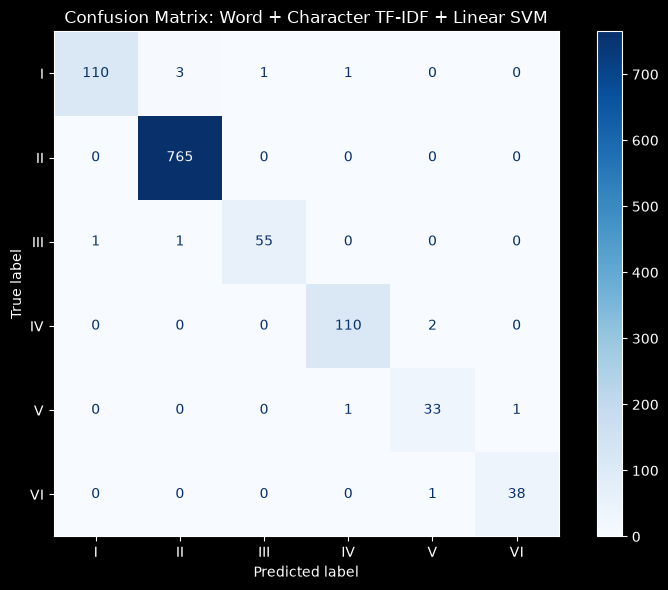

MLflow run ID: 555fc396501a48579d20a057d850a3ca

Результаты на test:
Macro-F1: 0.9717
Balanced accuracy: 0.9701
Количество ошибок: 12

Recall каждого класса:
Bethesda I: 0.9565
Bethesda II: 1.0000
Bethesda III: 0.9649
Bethesda IV: 0.9821
Bethesda V: 0.9429
Bethesda VI: 0.9744
🏃 View run prepared_word_char_tfidf_svm_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/555fc396501a48579d20a057d850a3ca
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [11]:
import sys
import sklearn
import matplotlib.pyplot as plt
import mlflow.sklearn

from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    recall_score,
    ConfusionMatrixDisplay,
)


# Фиксируем порядок категорий Bethesda
classes = ["I", "II", "III", "IV", "V", "VI"]


with mlflow.start_run(
    run_name="prepared_word_char_tfidf_svm_baseline"
) as run:

    # Общая информация об эксперименте
    mlflow.log_params({
        "participant": participant,
        "task_name": task_name,
        "run_date": run_date,
        "git_commit": git_commit,
        "dataset_name": dataset_path.name,
        "dataset_version": dataset_hash,
        "model_name": "Word + Character TF-IDF + Linear SVM",
        "train_size": len(X_train),
        "test_size": len(X_test),
        "test_size_ratio": 0.2,
        "split_random_state": 42,
        "python_version": sys.version.split()[0],
        "sklearn_version": sklearn.__version__,
    })

    # Параметры словного TF-IDF
    mlflow.log_params({
        "word_tfidf_ngram_range": str(
            word_tfidf_params_svm1["ngram_range"]
        ),
        "word_tfidf_min_df": word_tfidf_params_svm1["min_df"],
        "word_tfidf_lowercase": word_tfidf_params_svm1["lowercase"],
    })

    # Параметры символьного TF-IDF
    mlflow.log_params({
        "char_tfidf_analyzer": char_tfidf_params_svm1["analyzer"],
        "char_tfidf_ngram_range": str(
            char_tfidf_params_svm1["ngram_range"]
        ),
        "char_tfidf_min_df": char_tfidf_params_svm1["min_df"],
        "char_tfidf_lowercase": char_tfidf_params_svm1["lowercase"],
    })

    # Параметры Linear SVM
    mlflow.log_params({
        "svm_C": svm_params_run1["C"],
        "svm_class_weight": svm_params_run1["class_weight"],
        "svm_max_iter": svm_params_run1["max_iter"],
        "svm_random_state": svm_params_run1["random_state"],
    })

    # Обучаем модель на train
    model_svm_run1.fit(X_train, y_train)

    # Получаем предсказания на test
    y_pred_svm_run1 = model_svm_run1.predict(X_test)

    # Рассчитываем основные метрики
    macro_f1_svm_run1 = f1_score(
        y_test,
        y_pred_svm_run1,
        average="macro",
    )

    balanced_acc_svm_run1 = balanced_accuracy_score(
        y_test,
        y_pred_svm_run1,
    )

    recall_per_class_svm_run1 = recall_score(
        y_test,
        y_pred_svm_run1,
        labels=classes,
        average=None,
        zero_division=0,
    )

    # Количество ошибок на тестовой выборке
    errors_svm_run1 = int(
        (y_test.to_numpy() != y_pred_svm_run1).sum()
    )

    # Сохраняем метрики в MLflow
    mlflow.log_metrics({
        "macro_f1": macro_f1_svm_run1,
        "balanced_accuracy": balanced_acc_svm_run1,
        "test_errors": errors_svm_run1,
    })

    # Сохраняем recall для каждого класса
    for class_name, recall_value in zip(
        classes,
        recall_per_class_svm_run1,
    ):
        mlflow.log_metric(
            f"recall_bethesda_{class_name}",
            recall_value,
        )

    # Строим матрицу ошибок
    fig, ax = plt.subplots(figsize=(8, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred_svm_run1,
        labels=classes,
        ax=ax,
        cmap="Blues",
        values_format="d",
    )

    ax.set_title(
        "Confusion Matrix: Word + Character TF-IDF + Linear SVM"
    )

    plt.tight_layout()

    # Сохраняем матрицу ошибок в MLflow
    mlflow.log_figure(
        fig,
        "confusion_matrix.png",
    )

    plt.show()
    plt.close(fig)

    # Сохраняем обученный Pipeline локально в MLflow
    mlflow.sklearn.log_model(
        sk_model=model_svm_run1,
        name="model",
    )

    # Выводим результаты эксперимента
    print("MLflow run ID:", run.info.run_id)

    print("\nРезультаты на test:")
    print(f"Macro-F1: {macro_f1_svm_run1:.4f}")
    print(f"Balanced accuracy: {balanced_acc_svm_run1:.4f}")
    print(f"Количество ошибок: {errors_svm_run1}")

    print("\nRecall каждого класса:")

    for class_name, recall_value in zip(
        classes,
        recall_per_class_svm_run1,
    ):
        print(
            f"Bethesda {class_name}: "
            f"{recall_value:.4f}"
        )

### Вывод по эксперименту 1

Модель Linear SVM с C=1.0 достигла macro-F1 = 0.9717
и balanced accuracy = 0.9701.

На тестовой выборке из 1123 записей модель допустила
12 ошибок. Наиболее сложной категорией по recall
оказалась Bethesda V (0.9429).

По сравнению с лучшей Logistic Regression (macro-F1 = 0.9725)
Linear SVM показала близкое качество, но не превзошла
первую модель.

Для дальнейшего исследования необходимо подобрать
параметр регуляризации C с использованием
кросс-валидации на обучающей выборке.


## Эксперимент 2. Подбор параметра регуляризации C для Linear SVM

### Цель эксперимента

Определить оптимальное значение параметра регуляризации `C` для модели Linear SVM с помощью стратифицированной кросс-валидации.

В первом эксперименте модель с `C=1.0` показала следующие результаты:

- Macro-F1: 0.9717
- Balanced accuracy: 0.9701
- Количество ошибок на test: 12

Полученные показатели близки к результатам Logistic Regression, однако дополнительная настройка регуляризации может улучшить качество классификации.

### Методика эксперимента

В эксперименте сохраняются:

- Датасет `prepared_dataset.csv` без дополнительной очистки.
- Разделение train/test: 80/20, `random_state=42`.
- Word TF-IDF: `ngram_range=(1, 2)`.
- Character TF-IDF: `analyzer="char_wb"`, `ngram_range=(3, 5)`.
- Балансировка классов: `class_weight="balanced"`.

Проверяемые значения параметра `C`:

`[0.1, 0.5, 1.0, 2.0, 4.0, 10.0]`

Для подбора используется `GridSearchCV` с пятикратной стратифицированной кросс-валидацией (`StratifiedKFold`).

Основная метрика выбора оптимального параметра - средний Macro-F1 по пяти фолдам. Дополнительно рассчитывается balanced accuracy.

Все варианты оцениваются исключительно на обучающей выборке. Тестовая выборка не используется для выбора гиперпараметров.

### Ожидаемый результат

По итогам кросс-валидации необходимо:

1. Сравнить средние значения Macro-F1 и balanced accuracy для каждого `C`.
2. Определить оптимальное значение `C`.
3. Оценить выбранную модель на тестовой выборке.
4. Сравнить результат с Linear SVM из эксперимента 1 и Logistic Regression.
5. Сохранить параметры, метрики и модель в MLflow.


In [12]:
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
)


# Значения C для поиска оптимальной регуляризации
param_grid_svm_run2 = {
    "svm__C": [0.1, 0.5, 1.0, 2.0, 4.0, 10.0],
}

# Стратифицированная кросс-валидация на 5 фолдах
cv_svm_run2 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

# Метрики для сравнения параметров
scoring_svm_run2 = {
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
}

# Настраиваем поиск оптимального параметра C
grid_search_svm_run2 = GridSearchCV(
    estimator=model_svm_run1,
    param_grid=param_grid_svm_run2,
    scoring=scoring_svm_run2,
    refit="macro_f1",
    cv=cv_svm_run2,
    n_jobs=2,
    verbose=1,
    return_train_score=False,
)

print("GridSearchCV для Linear SVM создан.")
print("Проверяемые значения C:", param_grid_svm_run2["svm__C"])
print("Количество фолдов:", cv_svm_run2.n_splits)
print(
    "Количество CV-обучений:",
    len(param_grid_svm_run2["svm__C"]) * cv_svm_run2.n_splits,
)
print("Основная метрика: Macro-F1")

GridSearchCV для Linear SVM создан.
Проверяемые значения C: [0.1, 0.5, 1.0, 2.0, 4.0, 10.0]
Количество фолдов: 5
Количество CV-обучений: 30
Основная метрика: Macro-F1


In [ ]:

import sys
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import mlflow.sklearn

from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    recall_score,
    ConfusionMatrixDisplay,
)


with mlflow.start_run(
    run_name="prepared_word_char_tfidf_svm_tuned_C"
) as run:

    # Сохраняем информацию для воспроизводимости
    mlflow.log_params({
        "participant": participant,
        "task_name": task_name,
        "run_date": run_date,
        "git_commit": git_commit,
        "code_version": git_commit,
        "dataset_name": dataset_path.name,
        "dataset_version": dataset_hash,
        "model_name": "Word + Character TF-IDF + Linear SVM",
        "train_size": len(X_train),
        "test_size": len(X_test),
        "test_size_ratio": 0.2,
        "split_random_state": 42,
        "python_version": sys.version.split()[0],
        "sklearn_version": sklearn.__version__,
    })

    # Параметры словного TF-IDF
    mlflow.log_params({
        "word_tfidf_ngram_range": str(
            word_tfidf_params_svm1["ngram_range"]
        ),
        "word_tfidf_min_df": word_tfidf_params_svm1["min_df"],
        "word_tfidf_lowercase": word_tfidf_params_svm1["lowercase"],
    })

    # Параметры символьного TF-IDF
    mlflow.log_params({
        "char_tfidf_analyzer": char_tfidf_params_svm1["analyzer"],
        "char_tfidf_ngram_range": str(
            char_tfidf_params_svm1["ngram_range"]
        ),
        "char_tfidf_min_df": char_tfidf_params_svm1["min_df"],
        "char_tfidf_lowercase": char_tfidf_params_svm1["lowercase"],
    })

    # Параметры классификатора и поиска
    mlflow.log_params({
        "svm_class_weight": svm_params_run1["class_weight"],
        "svm_max_iter": svm_params_run1["max_iter"],
        "svm_random_state": svm_params_run1["random_state"],
        "tested_C_values": str(param_grid_svm_run2["svm__C"]),
        "cv_folds": cv_svm_run2.n_splits,
        "cv_scoring": "f1_macro",
        "cv_seed": 42,
    })

    # Подбираем C только на обучающей выборке
    grid_search_svm_run2.fit(X_train, y_train)

    # Получаем лучший параметр по среднему CV Macro-F1
    best_c_svm_run2 = grid_search_svm_run2.best_params_[
        "svm__C"
    ]

    best_cv_macro_f1_svm_run2 = (
        grid_search_svm_run2.best_score_
    )

    # Формируем таблицу всех результатов кросс-валидации
    cv_results_svm_run2 = pd.DataFrame({
        "C": [
            float(value)
            for value in grid_search_svm_run2.cv_results_[
                "param_svm__C"
            ]
        ],
        "cv_macro_f1_mean": grid_search_svm_run2.cv_results_[
            "mean_test_macro_f1"
        ],
        "cv_macro_f1_std": grid_search_svm_run2.cv_results_[
            "std_test_macro_f1"
        ],
        "cv_balanced_accuracy_mean": (
            grid_search_svm_run2.cv_results_[
                "mean_test_balanced_accuracy"
            ]
        ),
        "cv_balanced_accuracy_std": (
            grid_search_svm_run2.cv_results_[
                "std_test_balanced_accuracy"
            ]
        ),
        "rank": grid_search_svm_run2.cv_results_[
            "rank_test_macro_f1"
        ],
    })

    cv_results_svm_run2 = cv_results_svm_run2.sort_values(
        "C"
    ).reset_index(drop=True)

    print("\nРезультаты кросс-валидации:")
    print(
        cv_results_svm_run2.to_string(
            index=False,
            float_format=lambda value: f"{value:.4f}",
        )
    )

    # Сохраняем таблицу CV в MLflow
    mlflow.log_table(
        data=cv_results_svm_run2,
        artifact_file="cv_results.json",
    )

    # GridSearchCV уже переобучил лучшую модель на train
    model_svm_run2 = grid_search_svm_run2.best_estimator_

    # Оцениваем выбранную модель на test
    y_pred_svm_run2 = model_svm_run2.predict(X_test)

    macro_f1_svm_run2 = f1_score(
        y_test,
        y_pred_svm_run2,
        average="macro",
    )

    balanced_acc_svm_run2 = balanced_accuracy_score(
        y_test,
        y_pred_svm_run2,
    )

    recall_per_class_svm_run2 = recall_score(
        y_test,
        y_pred_svm_run2,
        labels=classes,
        average=None,
        zero_division=0,
    )

    # Подсчитываем ошибки на тестовой выборке
    errors_svm_run2 = int(
        (y_test.to_numpy() != y_pred_svm_run2).sum()
    )

    # Сохраняем лучший параметр и CV-метрику
    mlflow.log_param("best_C", best_c_svm_run2)

    mlflow.log_metrics({
        "best_cv_macro_f1": best_cv_macro_f1_svm_run2,
        "macro_f1": macro_f1_svm_run2,
        "balanced_accuracy": balanced_acc_svm_run2,
        "test_errors": errors_svm_run2,
    })

    # Сохраняем recall каждой категории
    for class_name, recall_value in zip(
        classes,
        recall_per_class_svm_run2,
    ):
        mlflow.log_metric(
            f"recall_bethesda_{class_name}",
            recall_value,
        )

    # Создаём матрицу ошибок
    fig, ax = plt.subplots(figsize=(8, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred_svm_run2,
        labels=classes,
        ax=ax,
        cmap="Blues",
        values_format="d",
    )

    ax.set_title(
        f"Linear SVM: tuned C={best_c_svm_run2}"
    )

    plt.tight_layout()

    # Сохраняем confusion matrix в MLflow
    mlflow.log_figure(
        fig,
        "confusion_matrix.png",
    )

    plt.show()
    plt.close(fig)

    # Сохраняем обученный Pipeline в локальном MLflow
    mlflow.sklearn.log_model(
        sk_model=model_svm_run2,
        name="model",
    )

    # Итоговые результаты эксперимента
    print("\nMLflow run ID:", run.info.run_id)
    print("Лучшее значение C:", best_c_svm_run2)

    print(
        f"Лучший CV Macro-F1: "
        f"{best_cv_macro_f1_svm_run2:.4f}"
    )

    print("\nРезультаты на test:")
    print(f"Macro-F1: {macro_f1_svm_run2:.4f}")
    print(
        f"Balanced accuracy: "
        f"{balanced_acc_svm_run2:.4f}"
    )
    print(f"Количество ошибок: {errors_svm_run2}")

    print("\nRecall каждого класса:")

    for class_name, recall_value in zip(
        classes,
        recall_per_class_svm_run2,
    ):
        print(
            f"Bethesda {class_name}: "
            f"{recall_value:.4f}"
        )
